This notebook was made to answer sub question 1 of this research project: is there a greater effect on the roads that changed from 50 to 30 km/h than on the roads without a change?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pyproj import Transformer
from matplotlib.collections import LineCollection

roads = pd.read_csv("DERTIG.csv", sep=";", encoding="utf-8-sig")
accidents = pd.read_csv("accidents_amsterdam_roadtype.csv")  # made with link_accidents_to_roads.py

print("Road segments:", len(roads))
print("Accidents:", len(accidents))
accidents.head()

Road segments: 25312
Accidents: 63291


,accident_id,year,severity,location_type,category,street,distance_m
0,20160000302,2016,DOD,road segment,other,`s-Gravelandseweg,0.0
1,20160000388,2016,DOD,intersection,already 30,Lutmastraat,0.1
2,20160000389,2016,DOD,road segment,already 30,Tollensstraat,0.4
3,20160000391,2016,DOD,road segment,already 30,Damrak,1.3
4,20160000392,2016,DOD,intersection,already 30,Korte Prinsengracht,0.4


In [2]:
print(accidents["category"].value_counts())
print()
print(f"Linked within 25 m: {100 * (accidents['category'] != 'not linked').mean():.1f}%")
print(f"Median distance to road: {accidents['distance_m'].median()} m")
print()
print(accidents["location_type"].value_counts())

category
other         20618
already 30    18881
50 to 30      16222
stayed 50      7200
not linked      370
Name: count, dtype: int64

Linked within 25 m: 99.4%
Median distance to road: 0.8 m

location_type
road segment    26276
intersection    20638
motorway        16377
Name: count, dtype: int64


In [3]:
def road_category(old, new):
    if old == "GOW50" and new in ("GOW30", "ETW30"):
        return "50 to 30"
    if old == "GOW50" and new == "GOW50":
        return "stayed 50"
    if old in ("ETW30", "GOW30") and new in ("ETW30", "GOW30"):
        return "already 30"
    return "other"


roads["category"] = [road_category(o, n) for o, n in zip(roads["WEGTYPE_OUD"], roads["WEGTYPE_NIEUW"])]

# convert from lat/lon to RD coordinates (metres)
to_rd = Transformer.from_crs("EPSG:4326", "EPSG:28992", always_xy=True)


def convert(xy):
    x, y = to_rd.transform(xy[:, 0], xy[:, 1])
    return np.column_stack([x, y])


lines = shapely.transform(shapely.from_wkt(roads["WKT"].values), convert)
roads["length_km"] = shapely.length(lines) / 1000

print(pd.crosstab(roads["WEGTYPE_OUD"], roads["WEGTYPE_NIEUW"]))
print()
print(roads.groupby("category").agg(segments=("OBJECTNUMMER", "size"), length_km=("length_km", "sum")).round(0))

WEGTYPE_NIEUW   BUITEN N  ETW30  ETW60  GOW30  GOW50  GOW70  SW80PLUS
WEGTYPE_OUD                                                          
BUITEN NETWERK         1     75      0     13      1      0         0
ETW30                  0  17007      0     11      1      0         0
ETW60                  0      1    110      0      2      0         0
GOW30                  0      0      0    287      0      0         0
GOW50                  0    814      0   3040   1800      0         0
GOW70                  0      0      0      0      0    113         0
SW80PLUS               0      0      0      0     14      0       504

            segments  length_km
category                       
50 to 30        3854      360.0
already 30     17305     1372.0
other           2353      583.0
stayed 50       1800      278.0


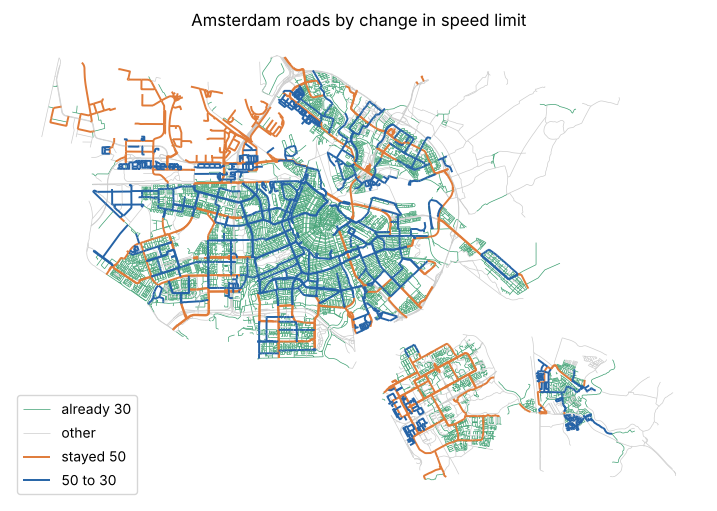

In [4]:
colors = {"50 to 30": "#2563A6", "stayed 50": "#E07B39", "already 30": "#3A9E6F", "other": "#CCCCCC"}
groups = ["50 to 30", "stayed 50", "already 30"]

fig, ax = plt.subplots(figsize=(9, 8))
for cat in ["already 30", "other", "stayed 50", "50 to 30"]:
    part = lines[(roads["category"] == cat).values]
    width = 1.4 if cat in ("50 to 30", "stayed 50") else 0.5
    ax.add_collection(LineCollection([np.asarray(g.coords) for g in shapely.get_parts(part)],
                                     colors=colors[cat], linewidths=width, label=cat))
ax.autoscale()
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(loc="lower left")
ax.set_title("Amsterdam roads by change in speed limit")
plt.savefig("RQ1_map_road_categories.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
data = accidents[accidents["category"].isin(groups)].copy()
data["period"] = "before"
data.loc[data["year"] == 2023, "period"] = "transition"
data.loc[data["year"] >= 2024, "period"] = "after"
data["serious"] = data["severity"].isin(["LET", "DOD"])
data["fatal"] = data["severity"] == "DOD"

pd.crosstab(data["category"], data["period"])[["before", "transition", "after"]]

period,before,transition,after
category,,,
50 to 30,11836,1628,2758
already 30,13580,1883,3418
stayed 50,4920,823,1457


In [6]:
def count_per_year(d):
    return (d.groupby(["category", "year"])
             .agg(accidents=("accident_id", "size"), serious=("serious", "sum"), fatal=("fatal", "sum"))
             .reset_index())


per_year = count_per_year(data)
per_year["% serious"] = (100 * per_year["serious"] / per_year["accidents"]).round(1)
per_year.pivot(index="year", columns="category", values=["accidents", "serious", "fatal", "% serious"])

accidents                       serious                       \
category  50 to 30 already 30 stayed 50 50 to 30 already 30 stayed 50   
year                                                                    
2016        1954.0     2470.0     687.0    551.0      587.0     144.0   
2017        1984.0     2281.0     748.0    504.0      547.0     164.0   
2018        1822.0     2211.0     708.0    432.0      488.0     148.0   
2019        1706.0     1955.0     740.0    372.0      403.0     149.0   
2020        1326.0     1333.0     592.0    324.0      290.0     121.0   
2021        1463.0     1548.0     653.0    314.0      296.0     116.0   
2022        1581.0     1782.0     792.0    384.0      403.0     154.0   
2023        1628.0     1883.0     823.0    399.0      415.0     164.0   
2024        1439.0     1697.0     750.0    433.0      421.0     156.0   
2025        1319.0     1721.0     707.0    401.0      460.0     161.0   

            fatal                      % serious                       
category 50 to 30 already 30 stayed 50  50 to 30 already 30 stayed 50  
year                                                                   
2016          1.0        7.0       1.0      28.2       23.8      21.0  
2017          4.0        4.0       1.0      25.4       24.0      21.9  
2018          9.0        2.0       1.0      23.7       22.1      20.9  
2019          4.0        3.0       6.0      21.8       20.6      20.1  
2020          2.0        5.0       3.0      24.4       21.8      20.4  
2021          3.0        6.0       3.0      21.5       19.1      17.8  
2022          3.0        4.0       4.0      24.3       22.6      19.4  
2023          6.0        2.0       3.0      24.5       22.0      19.9  
2024          7.0        5.0       5.0      30.1       24.8      20.8  
2025          6.0        5.0       5.0      30.4       26.7      22.8

In [7]:
without_2023 = per_year[per_year["year"] != 2023].copy()
without_2023["period"] = "before"
without_2023.loc[without_2023["year"] >= 2024, "period"] = "after"

summary = without_2023.groupby(["category", "period"])[["accidents", "serious", "fatal"]].mean()
summary = summary.unstack("period").round(1)
summary = summary[[(c, p) for c in ["accidents", "serious", "fatal"] for p in ["before", "after"]]]
for col in ["accidents", "serious", "fatal"]:
    summary[(col, "change %")] = (100 * (summary[(col, "after")] / summary[(col, "before")] - 1)).round(1)
summary.reindex(groups)

accidents         serious         fatal       accidents  serious  \
period        before   after  before  after before after  change % change %   
category                                                                      
50 to 30      1690.9  1379.0   411.6  417.0    3.7   6.5     -18.4      1.3   
stayed 50      702.9   728.5   142.3  158.5    2.7   5.0       3.6     11.4   
already 30    1940.0  1709.0   430.6  440.5    4.4   5.0     -11.9      2.3   

              fatal  
period     change %  
category             
50 to 30       75.7  
stayed 50      85.2  
already 30     13.6

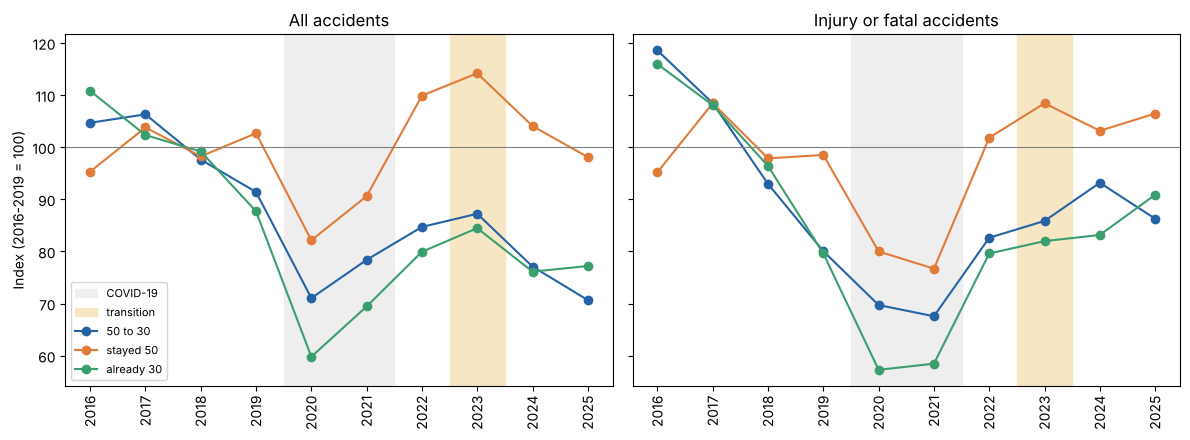

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (col, title) in zip(axes, [("accidents", "All accidents"), ("serious", "Injury or fatal accidents")]):
    ax.axvspan(2019.5, 2021.5, color="#EEEEEE", label="COVID-19")
    ax.axvspan(2022.5, 2023.5, color="#F7E6C4", label="transition")
    for cat in groups:
        d = per_year[per_year["category"] == cat].set_index("year")[col]
        ax.plot(d.index, 100 * d / d.loc[2016:2019].mean(), marker="o", color=colors[cat], label=cat)
    ax.axhline(100, color="grey", linewidth=0.8)
    ax.set_title(title)
    ax.set_xticks(range(2016, 2026))
    ax.tick_params(axis="x", rotation=90)
axes[0].set_ylabel("Index (2016-2019 = 100)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("RQ1_index_per_category.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
def prepare(control, source=per_year, drop_years=(2023,)):
    d = source[source["category"].isin(["50 to 30", control]) & ~source["year"].isin(drop_years)].copy()
    d["treated"] = (d["category"] == "50 to 30").astype(int)
    d["after"] = (d["year"] >= 2024).astype(int)
    d["t"] = d["year"] - 2016
    return d


def poisson(d, formula, term):
    m = smf.glm(formula, data=d, family=sm.families.Poisson()).fit(scale="X2")
    est = np.exp(m.params[term])
    low, high = np.exp(m.conf_int().loc[term])
    return est, low, high, m.pvalues[term]


print("Pre-trend test (before years without COVID): yearly ratio treated vs control")
for control in ["stayed 50", "already 30"]:
    for measure in ["accidents", "serious"]:
        pre = prepare(control)
        pre = pre[pre["year"].isin([2016, 2017, 2018, 2019, 2022])]
        est, low, high, p = poisson(pre, f"{measure} ~ treated * t", "treated:t")
        print(control, measure, round(est, 3), "CI:", round(low, 3), "-", round(high, 3), "p =", round(p, 3))

Pre-trend test (before years without COVID): yearly ratio treated vs control
stayed 50 accidents 0.942 CI: 0.922 - 0.962 p = 0.0
stayed 50 serious 0.934 CI: 0.875 - 0.996 p = 0.038
already 30 accidents 1.016 CI: 0.995 - 1.037 p = 0.135
already 30 serious 1.004 CI: 0.945 - 1.065 p = 0.907


In [10]:
did_formula = "{m} ~ C(category) + C(year) + treated:after"
trend_formula = "{m} ~ C(category) + C(year) + treated:t + treated:after"

rows = []
for control in ["stayed 50", "already 30"]:
    for measure in ["accidents", "serious", "fatal"]:
        d = prepare(control)
        for model, formula in [("DiD", did_formula), ("DiD + trend", trend_formula)]:
            if model == "DiD + trend" and (measure == "fatal" or control == "already 30"):
                continue
            est, low, high, p = poisson(d, formula.format(m=measure), "treated:after")
            rows.append({"control": control, "measure": measure, "model": model, "IRR": est,
                         "CI low": low, "CI high": high, "p": p, "change %": 100 * (est - 1)})

did_results = pd.DataFrame(rows).round(3)
did_results

,control,measure,model,IRR,CI low,CI high,p,change %
0,stayed 50,accidents,DiD,0.787,0.655,0.945,0.010,-21.314
1,stayed 50,accidents,DiD + trend,1.069,0.997,1.146,0.059,6.916
2,stayed 50,serious,DiD,0.910,0.728,1.136,0.403,-9.046
3,stayed 50,serious,DiD + trend,1.284,1.037,1.590,0.022,28.407
4,stayed 50,fatal,DiD,0.950,0.319,2.826,0.927,-5.000
5,already 30,accidents,DiD,0.926,0.818,1.047,0.221,-7.420
6,already 30,serious,DiD,0.990,0.869,1.129,0.885,-0.965
7,already 30,fatal,DiD,1.550,0.451,5.325,0.486,55.000


In [11]:
rows = []
for control in ["stayed 50", "already 30"]:
    d = data[data["category"].isin(["50 to 30", control]) & (data["period"] != "transition")].copy()
    d["treated"] = (d["category"] == "50 to 30").astype(int)
    d["after"] = (d["period"] == "after").astype(int)
    d["serious"] = d["serious"].astype(int)
    m = smf.logit("serious ~ C(category) + C(year) + treated:after", data=d).fit(disp=False)
    low, high = np.exp(m.conf_int().loc["treated:after"])
    rows.append({"control": control, "OR": np.exp(m.params["treated:after"]),
                 "CI low": low, "CI high": high, "p": m.pvalues["treated:after"]})

pd.DataFrame(rows).round(3)

,control,OR,CI low,CI high,p
0,stayed 50,1.239,1.046,1.468,0.013
1,already 30,1.104,0.973,1.252,0.125


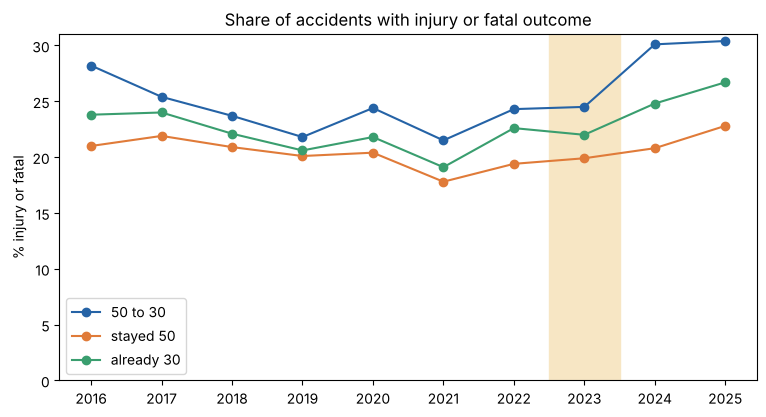

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(2022.5, 2023.5, color="#F7E6C4")
for cat in groups:
    d = per_year[per_year["category"] == cat]
    ax.plot(d["year"], d["% serious"], marker="o", color=colors[cat], label=cat)
ax.set_ylim(0, None)
ax.set_xticks(range(2016, 2026))
ax.set_ylabel("% injury or fatal")
ax.set_title("Share of accidents with injury or fatal outcome")
ax.legend()
plt.savefig("RQ1_share_serious_per_category.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
segments_only = count_per_year(data[data["location_type"] == "road segment"])
checks = {
    "main analysis": prepare("stayed 50"),
    "without 2020-2021": prepare("stayed 50", drop_years=(2020, 2021, 2023)),
    "road segments only": prepare("stayed 50", source=segments_only),
    "before = 2022 only": prepare("stayed 50", drop_years=(2016, 2017, 2018, 2019, 2020, 2021, 2023)),
}

rows = []
for name, d in checks.items():
    for measure in ["accidents", "serious"]:
        est, low, high, p = poisson(d, did_formula.format(m=measure), "treated:after")
        rows.append({"analysis": name, "measure": measure, "IRR": est, "CI low": low, "CI high": high, "p": p})

pd.DataFrame(rows).round(3)

,analysis,measure,IRR,CI low,CI high,p
0,main analysis,accidents,0.787,0.655,0.945,0.010
1,main analysis,serious,0.910,0.728,1.136,0.403
2,without 2020-2021,accidents,0.769,0.623,0.949,0.014
3,without 2020-2021,serious,0.890,0.684,1.158,0.387
4,road segments only,accidents,0.744,0.605,0.914,0.005
5,road segments only,serious,0.845,0.644,1.108,0.223
6,before = 2022 only,accidents,0.948,0.906,0.993,0.024
7,before = 2022 only,serious,1.055,0.876,1.272,0.573


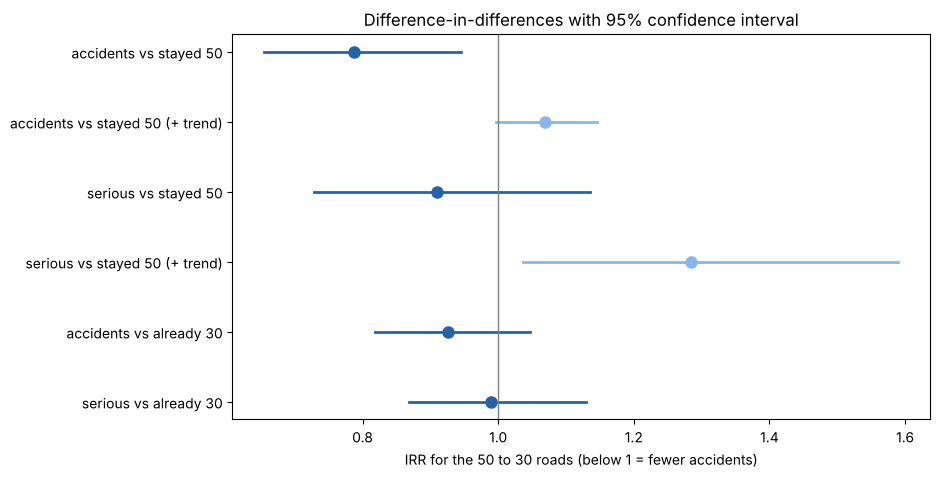

In [14]:
plot = did_results[(did_results["measure"] != "fatal")
                   & ~((did_results["control"] == "already 30") & (did_results["model"] == "DiD + trend"))]
labels = [f"{r.measure} vs {r.control}" + (" (+ trend)" if r.model == "DiD + trend" else "") for r in plot.itertuples()]

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(plot))[::-1]
for yi, (_, r) in zip(y, plot.iterrows()):
    color = "#86B6EF" if r["model"] == "DiD + trend" else "#2563A6"
    ax.plot([r["CI low"], r["CI high"]], [yi, yi], color=color, linewidth=2)
    ax.plot(r["IRR"], yi, "o", color=color, markersize=8)
ax.axvline(1, color="grey", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("IRR for the 50 to 30 roads (below 1 = fewer accidents)")
ax.set_title("Difference-in-differences with 95% confidence interval")
plt.savefig("RQ1_did_results.png", dpi=200, bbox_inches="tight")
plt.show()

The 50 to 30 roads show about 21% fewer accidents than the roads that stayed 50, but they were already dropping faster before 2023. With a correction for that trend, or compared with the streets that were already 30, there is no significant extra effect. The share of serious accidents went up on the changed roads because mainly light accidents disappeared.